# جلسهٔ ۲ — ماشینِ ۲۰ سؤالی

*درخت تصمیم را بخوان، بکش، و خودت بساز.*

In [1]:
# COURSE SETUP — identical in every session. Just run it. (5 seconds)
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

plt.rcParams["figure.figsize"] = (8, 4)
print("Setup OK — let's build some AI.")


Setup OK — let's build some AI.


# PART 0 — نمایش: ماشین بازیِ ۲۰ سؤالی را انجام می‌دهد

جلسهٔ قبل، ماشین با **یک سؤال** بازی کرد و توله‌سگ را گربه گفت.
حالا اجازه بدهیم **دو سؤال** بپرسد.


In [ ]:
# DEMO: one question vs two questions — is the puppy saved?
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]
# session-1 machine: only 1 question (depth 1)
one_q = DecisionTreeClassifier(max_depth=1, random_state=42).fit(X, y)

# today's machine: 2 questions (depth 2)
two_q = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X, y)

# the same old enemy: the puppy (2 kg, long ears — a small dog!)
puppy = pd.DataFrame({"weight": [2], "ear_length": [10]})
print("one question:  puppy ->", one_q.predict(puppy[X.columns])[0])
print("two questions: puppy ->", two_q.predict(puppy[X.columns])[0])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, model, title in [(axes[0], one_q, "depth 1 — only one question"),
                         (axes[1], two_q, "depth 2 — two questions")]:
    plot_tree(model, feature_names=list(X.columns),
              class_names=sorted(y.unique()),
              filled=True, fontsize=9, impurity=False, ax=ax)
    ax.set_title(title)
plt.tight_layout(); plt.show()


# PART A — جلسهٔ تدریس

*(این بخش را با معلم، در کلاس پر می‌کنیم.)*

## A1 — بازی خودمان، این بار با چشم ماشین

همان حیوانات همیشگی. ماشینِ جلسهٔ ۱ فقط **یک سؤال** می‌پرسید:
«وزن بیشتر از ۱۴؟» — همان خطِ قرمز. حالا کل بازی را می‌بینیم.


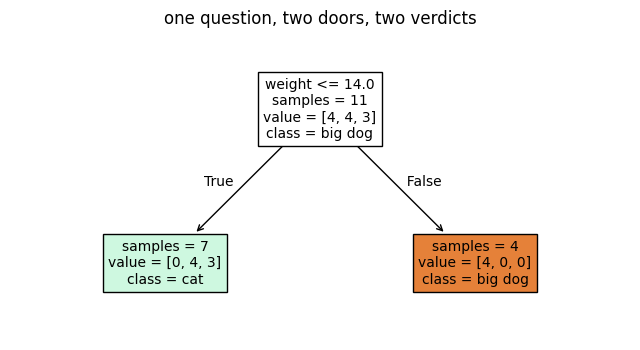

In [3]:
# A1 — the one-question tree: session 1's red line, drawn as a tree
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]
model = DecisionTreeClassifier(max_depth=1, random_state=42).fit(X, y)
plt.figure(figsize=(8, 4))
plot_tree(model, feature_names=list(X.columns),
          class_names=sorted(y.unique()),
          filled=True, fontsize=10, impurity=False)
plt.title("one question, two doors, two verdicts")
plt.show()
# session 1's red line and this picture are the same thing — only the drawing differs.


## A2 — ماشین با دو سؤال بازی می‌کند

سه گروه داریم: گربه، سگ بزرگ، سگ کوچک. یک سؤال برای سه گروه کافی نیست.


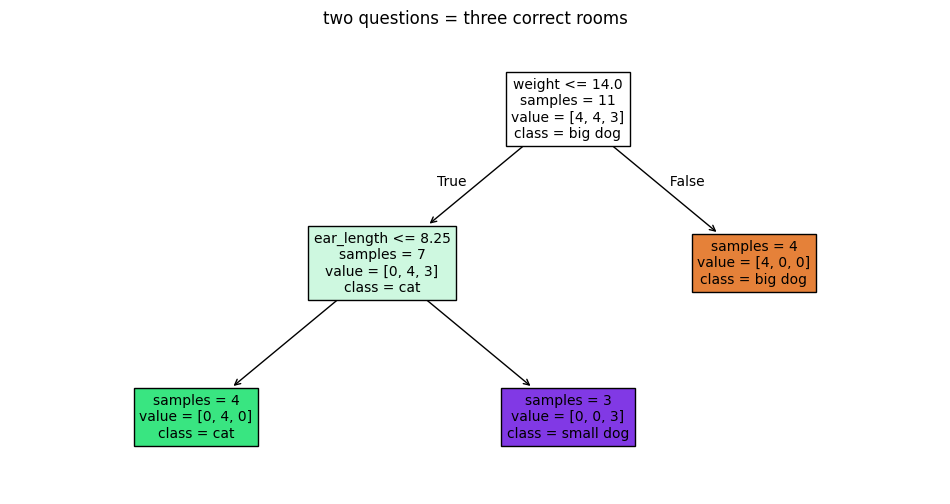

In [4]:
# A2 — the two-question tree: first question, second question, three final rooms
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]
model = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X, y)
plt.figure(figsize=(12, 6))
plot_tree(model, feature_names=list(X.columns),
          class_names=sorted(y.unique()),
          filled=True, fontsize=10, impurity=False)
plt.title("two questions = three correct rooms")
plt.show()


## A3 — درخت را بخوان: مسیر هر حیوان

قانون بازی: از بالای درخت شروع کن، به جوابِ هر سؤال، دنبالِ درِ مناسب را برو.
در آخرین اتاق (برگ)، حکم گفته می‌شود.


In [5]:
# A3 — trace a few animals' paths. Guess before you run, then check!
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]
model = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X, y)

visitors = pd.DataFrame({
    "weight": [35, 2, 3000],
    "ear_length": [10, 10, 20],
}, index=["wolf", "puppy", "elephant"])

answers = model.predict(visitors[X.columns])
for name, ans in zip(visitors.index, answers):
    print(f"  {name:10} -> {ans}")

# nice detail: the elephant hears only ONE question! its weight > 14, so it goes straight to the "big dog" leaf room.
# the ear question lives only in the light-animals corridor.
# a leaf always says one verdict — for whoever arrives there.


  wolf       -> big dog
  puppy      -> small dog
  elephant   -> big dog


## A4 — پیچ عمق: چند سؤال اجازه داریم؟

`max_depth` یعنی حداکثر تعداد سؤالی که ماشین اجازه دارد بپرسد.
با ۱ سؤال توله‌سگ گربه می‌شود. با ۲ سؤال درست می‌شود. خودت ببین.


In [6]:
# A4 — depth 1 vs depth 2: the puppy's mistake and its cure
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]
puppy = pd.DataFrame({"weight": [2], "ear_length": [10]})

for depth in (1, 2):
    model = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X, y)
    verdict = model.predict(puppy[X.columns])[0]
    correct = (model.predict(X) == y).mean()
    print(f"depth {depth}: puppy -> {verdict}   |   correct on 11 animals: {correct:.0%}")


depth 1: puppy -> cat   |   correct on 11 animals: 73%
depth 2: puppy -> small dog   |   correct on 11 animals: 100%


## A5 — دستت را روی پیچ بگذار

عمق را خودت عوض کن و دوباره اجرا کن. کوچک‌ترین عمقی که **هر ۱۱ حیوان را درست** دسته‌بندی می‌کند چیست؟


depth 2: 3 leaves, accuracy on 11 animals: 100%


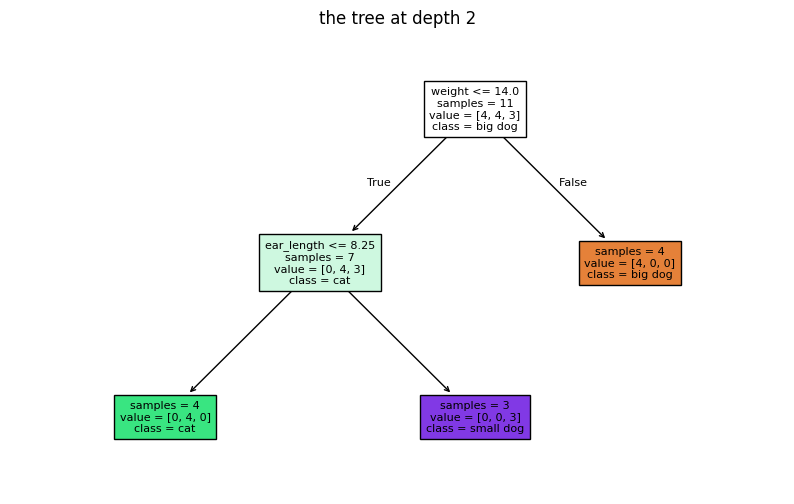

In [7]:
# A5 — the depth knob: change the number, run, watch
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]
max_depth = 2   # <-- change this: 1, 2, 3, 5, 10

model = DecisionTreeClassifier(max_depth=max_depth, random_state=42).fit(X, y)
correct = (model.predict(X) == y).mean()
leaves = model.get_n_leaves()
print(f"depth {max_depth}: {leaves} leaves, accuracy on 11 animals: {correct:.0%}")

plt.figure(figsize=(10, 6))
plot_tree(model, feature_names=list(X.columns),
          class_names=sorted(y.unique()),
          filled=True, fontsize=8, impurity=False)
plt.title(f"the tree at depth {max_depth}")
plt.show()


## A6 — درختِ تو، درختِ ماشین

درختت را روی کاغذ کشیدی؟ حالا کنارِ درخت ماشین بگذارش.
هر دو یک کار می‌کنند: سؤال، در، سؤال، در، حکم.


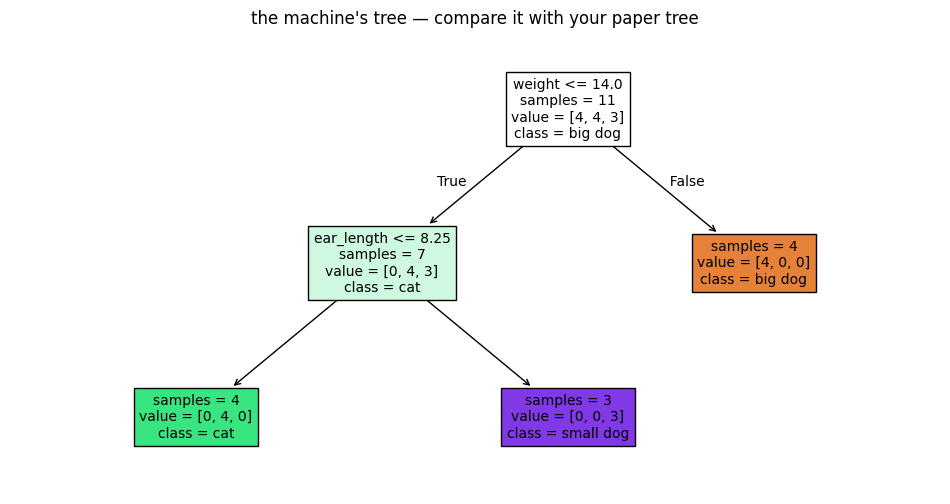

write down the similarity: what was your first question? the same as the machine's?


In [8]:
# A6 — the machine's final tree, next to your paper tree
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]
model = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X, y)
plt.figure(figsize=(12, 6))
plot_tree(model, feature_names=list(X.columns),
          class_names=sorted(y.unique()),
          filled=True, fontsize=10, impurity=False)
plt.title("the machine's tree — compare it with your paper tree")
plt.show()
print("write down the similarity: what was your first question? the same as the machine's?")


---

# PART B — تمرین‌های خانه (قبل از جلسهٔ حل مسئله)

## تمرین B1 — شمارندهٔ برگ و سؤال (۱ نمره)

به درختِ عمق ۲ نگاه کن (سلول A2). چند سؤال می‌پرسد؟ چند برگ دارد؟


In [9]:
# B1 — build the depth-2 tree and count
from sklearn.tree import DecisionTreeClassifier

B1_model = DecisionTreeClassifier(max_depth=2, random_state=42)
# TODO: train the model on X and y (from PART A) — fit
# TODO: fill B1_num_questions and B1_num_leaves (integers)

B1_num_questions = 0   # <-- your answer
B1_num_leaves = 0      # <-- your answer
print(f"questions: {B1_num_questions}, leaves: {B1_num_leaves}")


questions: 0, leaves: 0


## تمرین B2 — پیش‌بینی مسیر فیل (۱ نمره)

فیل (۳۰۰۰ کیلو، گوش ۲۰) از درختِ عمق ۲ رد می‌شود. به کدام اتاق می‌رسد؟


In [10]:
# B2 — what is the tree's verdict about the elephant?
# TODO: rebuild the depth-2 tree and put the elephant's prediction in B2_elephant_room
# (one of: "cat", "big dog", "small dog")

B2_elephant_room = ""   # <-- your answer
print("the elephant reaches this room:", B2_elephant_room)


the elephant reaches this room: 


## تمرین B3 — عمقِ درست را پیدا کن (۱ نمره)

کوچک‌ترین عمقی که هر ۱۱ حیوان را درست دسته‌بندی می‌کند چند است؟


In [11]:
# B3 — loop and find: the smallest perfect depth
best_depth = None
for depth in range(1, 6):
    m = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X, y)
    # TODO: complete the condition: if the model got all 11 animals right, this depth is the answer
    # (hint: (m.predict(X) == y).all() means "all correct")
    if False:
        best_depth = depth
        break

B3_min_depth = best_depth   # <-- your answer
print("the smallest perfect depth:", B3_min_depth)


the smallest perfect depth: None


---

# PART C — جلسهٔ حل مسئله

## C1 — باغ‌وحشِ غافلگیر: درختت را به آزمون بگذار

حیواناتی که در جدول نیستند. حکمِ درخت را قبل از اجرا حدس بزن — بعد چک کن.
کدام حیوانات قربانی اتاق‌های درخت می‌شوند؟


In [12]:
# C1 — surprise zoo: new visitors
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]
model = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X, y)

surprise_zoo = pd.DataFrame({
    "weight": [2, 8, 0.5, 0.03, 160],
    "ear_length": [10, 4, 3, 2, 20],
}, index=["rabbit", "fox", "hamster", "sparrow", "lion"])

guesses = model.predict(surprise_zoo[X.columns])
for name, ans in zip(surprise_zoo.index, guesses):
    print(f"  {name:8} -> {ans}")
# discussion: which verdicts are funny? why? which question of our tree caused the trouble?


  rabbit   -> small dog
  fox      -> cat
  hamster  -> cat
  sparrow  -> cat
  lion     -> big dog


## C2 — جراحی درخت: دو عمل جراحی، یک نتیجهٔ غافلگیرکن

خرگوش به اتاقِ «سگ کوچک» رفت. دو جراحی امتحان می‌کنیم:
جراحی اول: سؤال‌های بیشتری اجازه بده (عمق بیشتر).
جراحی دوم: مثال‌های بیشتری به ماشین بده (سگ‌های کوچکِ بیشتر).
هر دو را اجرا کن و ببین حکمِ خرگوش عوض می‌شود یا نه.


In [13]:
# C2 — two surgeries: more depth? more examples?
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]
surprise_zoo = pd.DataFrame({
    "weight": [2, 8, 0.5, 0.03, 160],
    "ear_length": [10, 4, 3, 2, 20],
}, index=["rabbit", "fox", "hamster", "sparrow", "lion"])

# surgery 1: more depth — finer questions
deep = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X, y)

# surgery 2: more examples — add 4 new small dogs to the table
extra_dogs = pd.DataFrame({"weight": [7, 8, 6.5, 9], "ear_length": [8.5, 9, 8, 9.5],
                           "group": ["small dog"] * 4})
X_fed = pd.concat([X, extra_dogs[["weight", "ear_length"]]])
y_fed = pd.concat([y, extra_dogs["group"]])
fed = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X_fed, y_fed)

base = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X, y)
print(f"{'animal':10} | base     | deeper   | more-data")
for name, a, b, c in zip(surprise_zoo.index,
                         base.predict(surprise_zoo),
                         deep.predict(surprise_zoo),
                         fed.predict(surprise_zoo)):
    print(f"  {name:8} | {a:8} | {b:8} | {c}")
print()
print("the rabbit in all three surgeries: small dog. why? because no question about")
print("weight or ear length separates a rabbit from a poodle. those two numbers are not enough.")
print("the real cure: a better question about something we did not measure — next session.")


animal     | base     | deeper   | more-data
  rabbit   | small dog | small dog | small dog
  fox      | cat      | cat      | cat
  hamster  | cat      | cat      | cat
  sparrow  | cat      | cat      | cat
  lion     | big dog  | big dog  | big dog

the rabbit in all three surgeries: small dog. why? because no question about
weight or ear length separates a rabbit from a poodle. those two numbers are not enough.
the real cure: a better question about something we did not measure — next session.


## C3 — بحث: درختِ کاغذیِ تو در برابر درختِ ماشین

اولین سؤالِ تو همانِ ماشین بود؟ اگر نه، درختِ تو هم درست کار می‌کرد؟
پس چند «درختِ درست» برای این جدول وجود دارد؟
